# Keep Page Coordinates with Your RAG Chunks

Build RAG chunks from PyMuPDF's layout boxes so every chunk remembers the page and region it came from, store them in LangChain or LlamaIndex, and render the source of any retrieved chunk.

Companion notebook for the article [Keep Page Coordinates with Your RAG Chunks](https://pymupdf.io/blog/keep-page-coordinates-with-your-rag-chunks) in the PyMuPDF grounding series. Tested with PyMuPDF 2.1.

In [1]:
%pip install -q pymupdf langchain-core llama-index-core


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## Sample document
Creates the sample PDF used in the article. Replace the path with your own PDF to try it on real documents.

In [2]:
import pymupdf
doc = pymupdf.open()
sections = [
 ("Acme Corporation Annual Report 2025", None),
 ("1. Financial highlights", "Net revenue increased 12% to $4.1 billion, driven by growth in the enterprise software segment. Operating margin improved to 18.4%, compared with 16.9% in the prior year. The company returned $350 million to shareholders through dividends and share repurchases."),
 ("2. Outlook", "Management expects revenue growth of 8% to 10% in fiscal 2026, with continued investment in cloud infrastructure and data centers in Europe and Asia. Capital expenditure is expected to reach $600 million."),
 ("3. Risk factors", "The company depends on a small number of large customers. In fiscal 2025, the three largest customers accounted for 31% of net revenue. The loss of any of these customers could materially affect results."),
 ("4. Supply chain", "Supply chain disruptions in 2024 delayed shipments of hardware appliances by up to six weeks. These delays did not recur in 2025, and inventory levels returned to normal by the second quarter."),
]
page = doc.new_page(); y = 72
for i,(h,body) in enumerate(sections):
    if i == 3:
        page = doc.new_page(); y = 72
    size = 18 if i == 0 else 14
    page.insert_text((72, y+size), h, fontsize=size, fontname="hebo"); y += size + 14
    if body:
        r = pymupdf.Rect(72, y, 400, y+200)
        rc = page.insert_textbox(r, body, fontsize=11, fontname="helv")
        y += 200 - rc + 18
doc.save("acme_report.pdf")

## What PyMuPDF already gives you

With `page_chunks=True`, `Document.to_markdown(`) returns one dictionary per page. Besides the page's Markdown text, each dictionary has page_boxes: the layout boxes on the page in reading order. Every box has a class (such as text, section-header or table), a `bbox` on the page, and a `pos` range that says which part of the Markdown the box produced.

In [3]:
import pymupdf

doc = pymupdf.open("acme_report.pdf")
for page_dict in doc.to_markdown(page_chunks=True):
    text = page_dict["text"]
    for box in page_dict["page_boxes"]:
        start, stop = box["pos"]
        print(page_dict["metadata"]["page_number"], box["class"], box["bbox"], repr(text[start:stop][:45]))

rapidocr_api using backend: rapidocr

=== Document parser messages ===
Using RapidOCR for OCR processing.
1 section-header (72, 76, 404, 94) '# **Acme Corporation Annual Report 2025** \n\n'
1 section-header (72, 107, 220, 122) '## **1. Financial highlights** \n\n'
1 text (72, 135, 400, 212) 'Net revenue increased 12% to $4.1 billion, dr'
1 section-header (72, 232, 141, 244) '## **2. Outlook** \n\n'
1 text (72, 260, 395, 318) 'Management expects revenue growth of 8% to 10'
2 section-header (72, 75, 168, 87) '## **3. Risk factors** \n\n'
2 text (72, 103, 398, 161) 'The company depends on a small number of larg'
2 section-header (72, 185, 175, 199) '## **4. Supply chain** \n\n'
2 text (72, 213, 396, 257) 'Supply chain disruptions in 2024 delayed ship'


So `text[start:stop]` is the Markdown from one box, and `bbox` is where that box sits on the page: `(x0, y0, x1, y1)` in points (72 per inch), measured from the top-left corner of the page and rounded to whole points. Layout analysis is on by default in PyMuPDF 2.x, so there is nothing extra to install.

## Step 1: Build chunks that remember where they came from

Instead of splitting the Markdown text with a generic splitter, which throws the positions away, build chunks from the boxes. This version starts a new chunk at each section header, so chunks follow the document's structure, and also starts one when a chunk grows past a size limit. Each chunk records the page and `bbox` of every box it contains, so chunks can span pages.

In [4]:
import json
import pymupdf


def chunks_with_coordinates(path, max_chars=1500):
    """Split a PDF into Markdown chunks that remember where each part came from.

    A new chunk starts at each section header, or when a chunk would exceed max_chars.
    Each chunk records the page number and bbox of every layout box it contains.
    """
    doc = pymupdf.open(path)
    chunks, current = [], None
    for page_dict in doc.to_markdown(page_chunks=True):
        page_number = page_dict["metadata"]["page_number"]      # 1-based
        text = page_dict["text"]
        for box in page_dict["page_boxes"]:
            start, stop = box["pos"]
            box_text = text[start:stop]
            is_header = box["class"] in ("title", "section-header")
            new_section = is_header and current and current["has_body"]
            too_long = current and len(current["text"]) + len(box_text) > max_chars
            if current is None or new_section or too_long:
                current = {"text": "", "boxes": [], "has_body": False}
                chunks.append(current)
            current["text"] += box_text
            current["has_body"] |= not is_header
            current["boxes"].append({"page": page_number, "bbox": list(box["bbox"])})
    return chunks

## Step 2: Store the coordinates as metadata

Most vector stores accept only flat metadata: strings, numbers and booleans. So keep the first page as a number, for filtering, and store the full list of boxes as a JSON string:

In [5]:
def chunk_metadata(path, chunk):
    """Flat metadata that vector stores accept: strings and numbers only."""
    return {
        "source": path,
        "page": chunk["boxes"][0]["page"],                 # first page, for filtering
        "boxes": json.dumps(chunk["boxes"]),               # every page and bbox
    }

```
{
  "source": "acme_report.pdf",
  "page": 1,
  "boxes": "[{\"page\": 1, \"bbox\": [72, 232, 141, 244]}, {\"page\": 1, \"bbox\": [72, 260, 395, 318]}]"
}
```

## Step 3: Load the chunks into LangChain or LlamaIndex

In LangChain, each chunk becomes a `Document`:

In [6]:
from langchain_core.documents import Document

path = "acme_report.pdf"
documents = [
    Document(page_content=c["text"], metadata=chunk_metadata(path, c))
    for c in chunks_with_coordinates(path)
]


=== Document parser messages ===
Using RapidOCR for OCR processing.


In LlamaIndex, each chunk becomes a `TextNode`. Exclude boxes from the text that is embedded and sent to the model, since coordinates mean nothing to either:

In [7]:
from llama_index.core.schema import TextNode

nodes = [
    TextNode(
        text=c["text"],
        metadata=chunk_metadata(path, c),
        excluded_embed_metadata_keys=["boxes"],   # keep coordinates out of the embedding
        excluded_llm_metadata_keys=["boxes"],     # and out of the prompt
    )
    for c in chunks_with_coordinates(path)
]


=== Document parser messages ===
Using RapidOCR for OCR processing.


From here, index the documents or nodes in any vector store as usual. The coordinates travel with every chunk.

## Step 4: Show where a retrieved chunk came from

When the retriever returns a chunk, its metadata tells you exactly which page regions to show. This function renders one image per page the chunk touches:

In [8]:
def chunk_images(metadata, dpi=150, margin=12):
    """Render the page regions a chunk came from: one image per page it touches."""
    doc = pymupdf.open(metadata["source"])
    regions = {}
    for b in json.loads(metadata["boxes"]):
        regions.setdefault(b["page"], pymupdf.Rect())
        regions[b["page"]] |= pymupdf.Rect(b["bbox"])
    images = []
    for page_number, rect in regions.items():
        page = doc[page_number - 1]
        clip = (rect + (-margin, -margin, margin, margin)) & page.rect
        images.append(page.get_pixmap(clip=clip, dpi=dpi))
    return images

In [9]:
# In a real pipeline this comes from your retriever, e.g. retriever.invoke("How much did revenue grow?")[0]
hit = next(d for d in documents if "Net revenue" in d.page_content)
for i, pix in enumerate(chunk_images(hit.metadata)):
    pix.save(f"source_{i}.png")

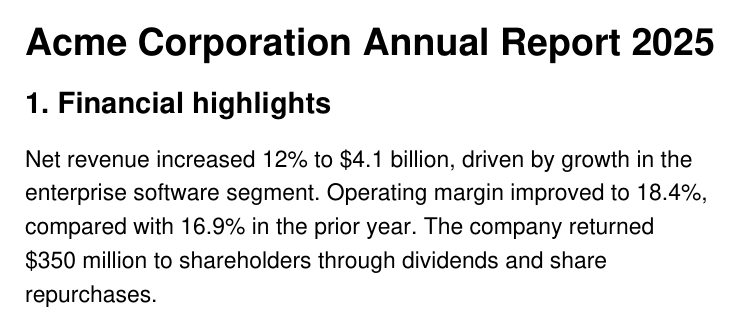

In [10]:
from IPython.display import Image, display
display(Image("source_0.png"))

Show these images next to the answer, or send the page numbers and boxes to your front end and draw them over the page there.

## Going further: from chunk to exact sentence

A chunk is often a whole section, while the model's answer usually rests on one sentence. Combine this article with the previous one: search for the quoted sentence only inside the chunk's regions. That keeps the search to the part of the page the chunk came from, so it cannot match the same sentence elsewhere in the document.

In [11]:
import json

def locate_in_chunk(doc, metadata, quote):
    """Find a quote inside a retrieved chunk's regions only."""
    for b in json.loads(metadata["boxes"]):
        page = doc[b["page"] - 1]
        quads = page.search_for(quote, clip=pymupdf.Rect(b["bbox"]), quads=True)
        if quads:
            return b["page"], quads
    return None, []

In [12]:
doc = pymupdf.open(path)
page_number, quads = locate_in_chunk(doc, hit.metadata, "Net revenue increased 12%")
print(page_number, [q.rect for q in quads])

1 [Rect(72.0, 132.00001525878906, 207.72897338867188, 147.114013671875)]


## Limits to know
- Coordinates are per layout box: a paragraph, heading, list item or table. For sentence-level positions, use the search shown above.
- A single box longer than the size limit stays in one chunk, because the boxes are never split.
- Scanned pages need OCR before they have text and boxes.
- The PyMuPDF loaders for LangChain and LlamaIndex do not pass page_boxes through today, so build the chunks yourself as shown here.

## Next steps

- Read the full article: https://pymupdf.io/blog/keep-page-coordinates-with-your-rag-chunks
- See everything on grounding with PyMuPDF: https://pymupdf.io/grounding